# Phase 20: final results
This notebook displays saved results. It does not retrain. Sections 1 to 7 of `REPORT.md` cover UNSW-NB15 and CICIDS2017 (`src/run_final.py`, `src/run_joint_full.py`, `src/extra_fixes.py`). The last three parts cover the zero-label work: the NetFlow test (`src/nf_transfer.py`, section 8), version 1 (`src/nf_zero_label.py`, section 9) and version 2 (`src/zero_label_v2.py`, section 10).

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
BASE = ROOT / 'outputs' / 'final_model'
T, P = BASE / 'tables', BASE / 'plots'
pd.set_option('display.max_colwidth', 90)
keep = ['direction', 'method', 'n', 'attack_rate', 'roc_auc', 'pr_auc', 'f1', 'precision', 'recall', 'fpr', 'trivial_f1']

## No labels from the test dataset
`trivial_f1` is the score from flagging every flow as an attack.

,regime,direction,method,n,attack_rate,roc_auc,pr_auc,f1,precision,recall,fpr,trivial_f1
0,baseline,UNSW->CICIDS,"RF 11 payload features, source threshold",1011866,0.220,0.409,0.187,0.220,0.156,0.372,0.569,NaN
1,baseline,UNSW->CICIDS,"RF + CORAL + balanced, source threshold",1011866,0.220,0.341,0.164,0.299,0.202,0.580,0.648,NaN
2,baseline,CICIDS->UNSW,"RF 11 payload features, source threshold",82332,0.551,0.550,0.558,0.000,0.000,0.000,0.000,NaN
3,baseline,CICIDS->UNSW,"RF + CORAL + balanced, source threshold",82332,0.551,0.738,0.762,0.000,0.000,0.000,0.000,NaN
4,transfer,UNSW->CICIDS,"ensemble, normalized, unlabeled threshold (all frozen days)",1011866,0.220,0.677,0.352,0.402,0.319,0.543,0.327,0.361
5,transfer,CICIDS->UNSW,"ensemble, normalized, unlabeled threshold (official file)",82332,0.551,0.476,0.521,0.354,0.440,0.296,0.462,0.710
6,transfer,CICIDS->UNSW,"ensemble, normalized, unlabeled threshold (full capture)",781874,0.083,0.676,0.174,0.223,0.132,0.719,0.426,0.153
7,transfer_selected,UNSW->CICIDS,"CORAL RF corrected log features, unlabeled threshold (all frozen days)",1011866,0.220,0.409,0.202,0.281,0.196,0.495,0.574,0.361
8,transfer_selected,CICIDS->UNSW,"CORAL RF corrected log features, unlabeled threshold (official file)",82332,0.551,0.781,0.794,0.747,0.701,0.799,0.419,0.710
9,transfer_selected,CICIDS->UNSW,"CORAL RF corrected log features, unlabeled threshold (full capture)",781874,0.083,0.830,0.256,0.407,0.289,0.691,0.153,0.153


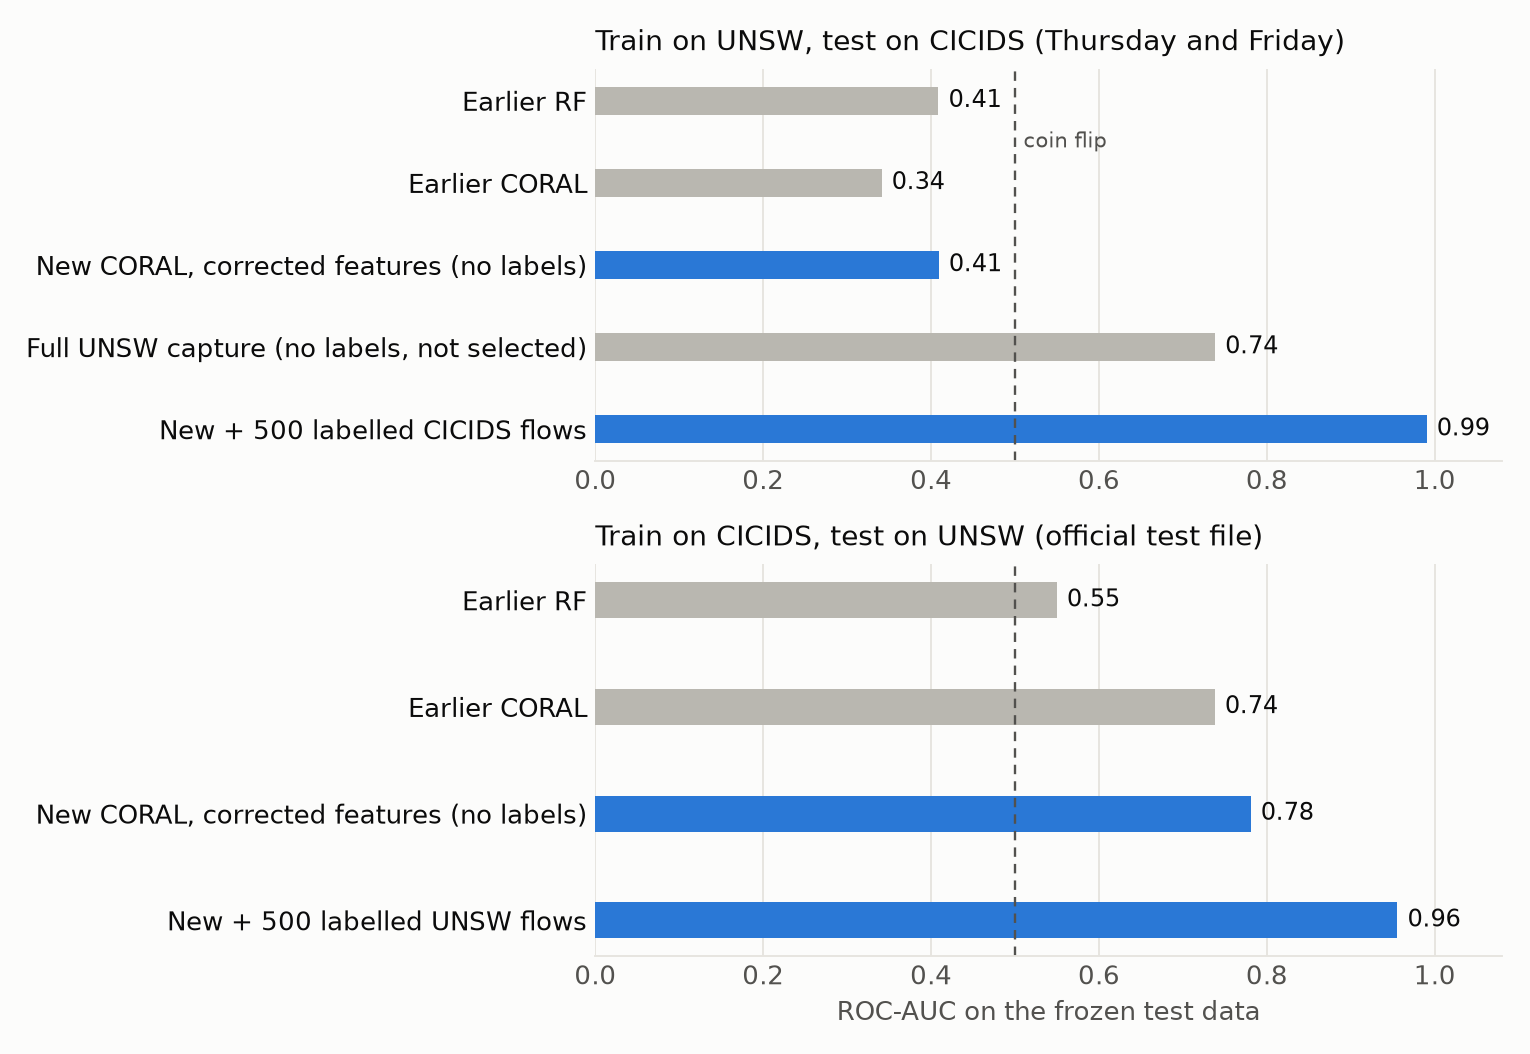

In [2]:
r = pd.read_csv(T / 'results.csv')
display(r[r.regime.str.startswith(('baseline', 'transfer'))][['regime'] + keep].round(3))
display(Image(P / '01_method_comparison_roc.png', width=720))

## One model trained on both datasets
Scored on the whole held-out test sets. The joint rows in `results.csv` used non-comparable halves of the sorted UNSW file and are replaced by this table.

In [3]:
display(pd.read_csv(T / 'joint_full_test.csv').round(3))
display(r[r.regime == 'joint_unseen_days'][keep].round(3))

,regime,dataset,test,n,attack_rate,roc_auc,pr_auc,f1,precision,recall,fpr,threshold
0,joint,UNSW,"official test, rows also in train removed",44900,0.333,0.955,0.927,0.758,0.629,0.953,0.279,0.69
1,joint,UNSW,"official test, all rows",82332,0.551,0.971,0.977,0.879,0.797,0.980,0.306,0.69
2,joint,CICIDS,"random 30%, duplicates removed",588220,0.161,1.000,1.000,0.994,0.994,0.993,0.001,0.69
3,within,UNSW,"official test, rows also in train removed",44900,0.333,0.956,0.929,0.755,0.622,0.961,0.291,0.40
4,within,UNSW,"official test, all rows",82332,0.551,0.966,0.973,0.879,0.795,0.981,0.309,0.40
5,within,CICIDS,"random 30%, duplicates removed",588220,0.161,1.000,1.000,0.996,0.998,0.993,0.000,0.90


,direction,method,n,attack_rate,roc_auc,pr_auc,f1,precision,recall,fpr,trivial_f1
15,both,"joint model, CICIDS test days excluded from training",1011866,0.22,0.758,0.648,0.534,0.968,0.368,0.003,NaN


## A small labelled sample from the test dataset

roc_auc            f1        precision        recall  \
                         mean    std   mean    std      mean    std   mean   
direction    labelled                                                        
CICIDS->UNSW 100        0.914  0.021  0.824  0.031     0.847  0.111  0.818   
             500        0.956  0.003  0.884  0.007     0.910  0.024  0.861   
             2000       0.971  0.001  0.908  0.002     0.912  0.005  0.905   
UNSW->CICIDS 100        0.978  0.005  0.714  0.122     0.791  0.223  0.746   
             500        0.990  0.002  0.892  0.010     0.949  0.024  0.842   
             2000       0.995  0.000  0.924  0.003     0.889  0.019  0.964   

                                fpr         
                         std   mean    std  
direction    labelled                       
CICIDS->UNSW 100       0.104  0.208  0.203  
             500       0.033  0.105  0.035  
             2000      0.002  0.108  0.006  
UNSW->CICIDS 100       0.281  0.093  0.129  
             500       0.034  0.013  0.007  
             2000      0.026  0.034  0.007

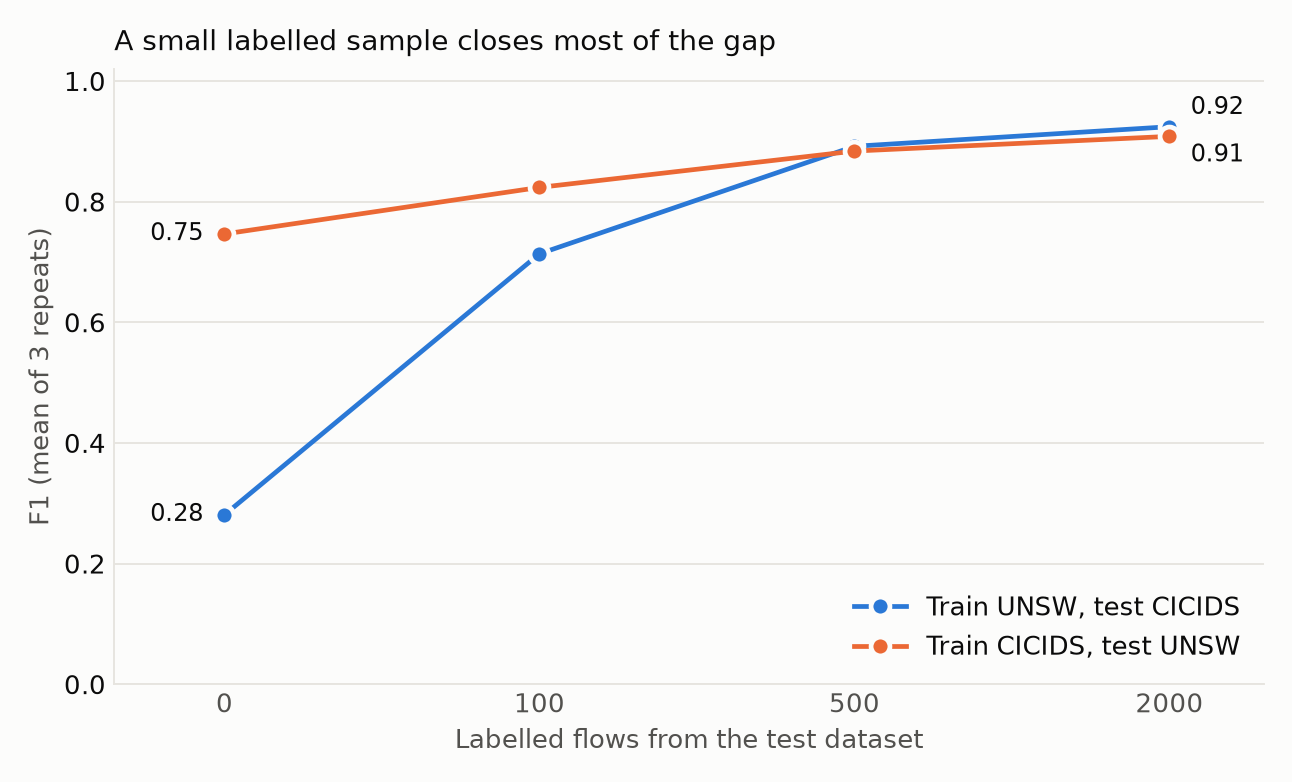

In [4]:
few = pd.read_csv(T / 'few_labels.csv')
display(few.groupby(['direction', 'labelled'])[['roc_auc', 'f1', 'precision', 'recall', 'fpr']].agg(['mean', 'std']).round(3))
display(Image(P / '02_labels_needed_f1.png', width=620))

## Attack families caught with no labels

,direction,eval,family,n,recall,roc_vs_benign
25,UNSW->CICIDS,all frozen days,Bot,1953,0.607,0.544
26,UNSW->CICIDS,all frozen days,DDoS,128011,0.834,0.531
27,UNSW->CICIDS,all frozen days,Infiltration,36,1.000,0.779
28,UNSW->CICIDS,all frozen days,PortScan,90768,0.004,0.225
29,UNSW->CICIDS,all frozen days,Web Attack ï¿½ Brute Force,1470,0.927,0.792
30,UNSW->CICIDS,all frozen days,Web Attack ï¿½ Sql Injection,21,0.571,0.636
31,UNSW->CICIDS,all frozen days,Web Attack ï¿½ XSS,652,0.988,0.828
32,CICIDS->UNSW,official file,Analysis,677,0.917,0.861
33,CICIDS->UNSW,official file,Backdoor,583,0.925,0.859
34,CICIDS->UNSW,official file,DoS,4089,0.781,0.760


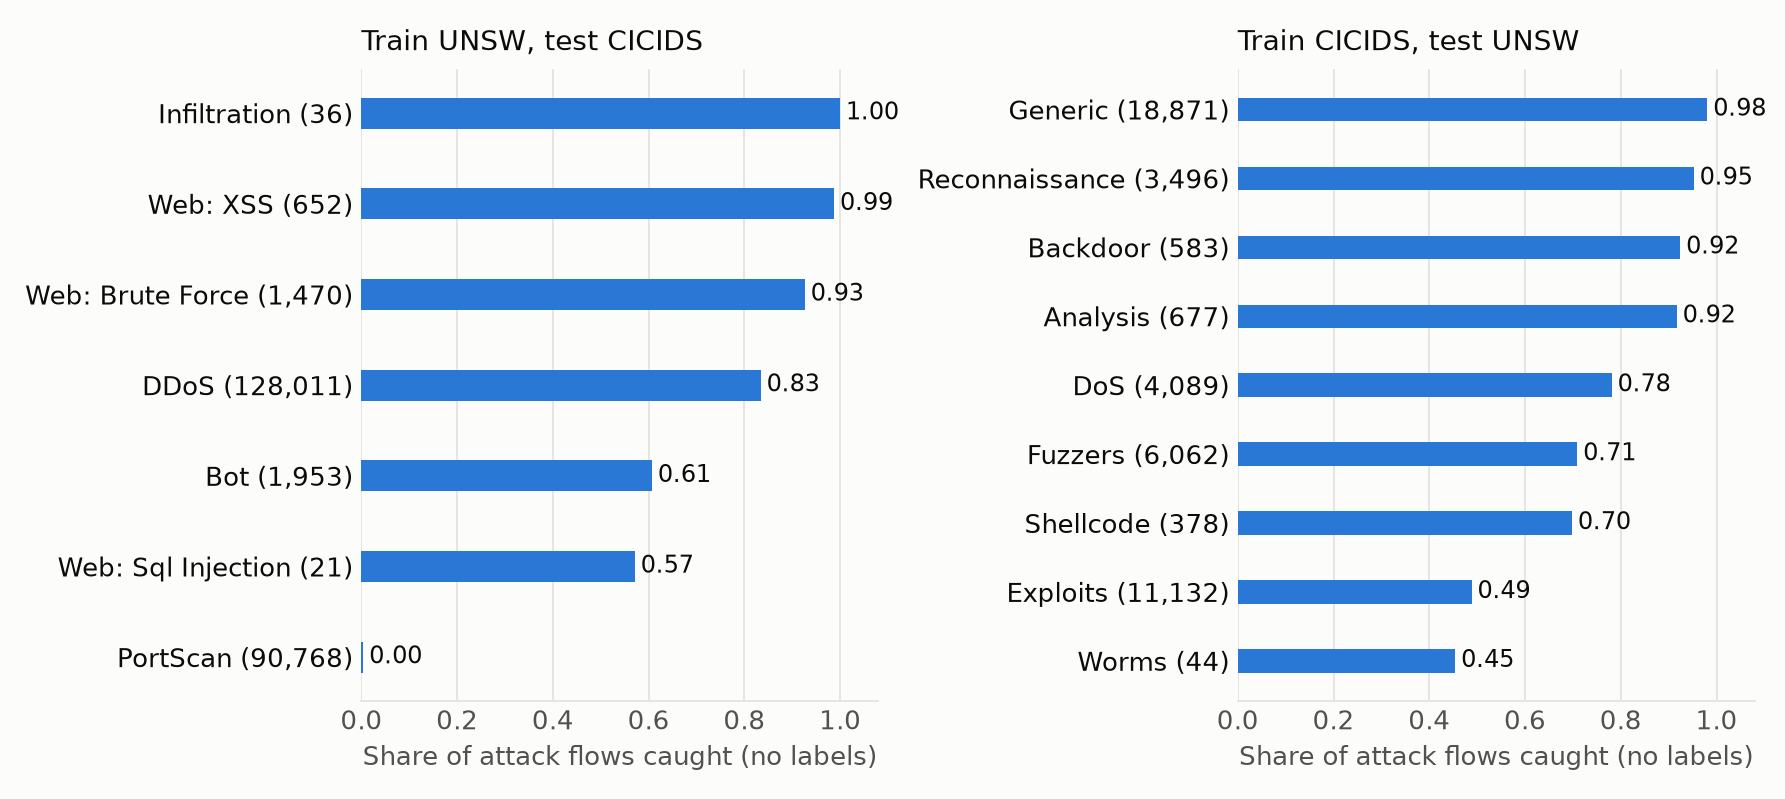

In [5]:
f = pd.read_csv(T / 'transfer_by_attack_family.csv')
display(f[f.method == 'selected'].drop(columns='method').round(3))
display(Image(P / '03_recall_by_attack_family.png', width=820))

## Development results
These guided method choices and are shown for comparison with the final data.

In [6]:
d = pd.read_csv(BASE / 'tables_dev' / 'results.csv')
display(d[['regime'] + keep].round(3))

,regime,direction,method,n,attack_rate,roc_auc,pr_auc,f1,precision,recall,fpr,trivial_f1
0,baseline,UNSW->CICIDS,"RF 11 payload features, source threshold",1481723,0.134,0.627,0.158,0.321,0.194,0.930,0.602,NaN
1,baseline,UNSW->CICIDS,"RF + CORAL + balanced, source threshold",1481723,0.134,0.765,0.253,0.290,0.172,0.909,0.679,NaN
2,baseline,CICIDS->UNSW,"RF 11 payload features, source threshold",175341,0.681,0.586,0.715,0.000,0.000,0.000,0.000,NaN
3,baseline,CICIDS->UNSW,"RF + CORAL + balanced, source threshold",175341,0.681,0.787,0.881,0.000,0.000,0.000,0.000,NaN
4,transfer,UNSW->CICIDS,"ensemble, normalized, unlabeled threshold (all frozen days)",1481723,0.134,0.683,0.189,0.332,0.201,0.941,0.580,0.237
5,transfer,CICIDS->UNSW,"ensemble, normalized, unlabeled threshold (official file)",175341,0.681,0.535,0.705,0.428,0.643,0.321,0.380,0.810
6,transfer,CICIDS->UNSW,"ensemble, normalized, unlabeled threshold (full capture)",1277540,0.027,0.680,0.072,0.081,0.043,0.701,0.440,0.053
7,joint,both,"joint model, tested on UNSW",22450,0.248,0.997,0.990,0.938,0.900,0.978,0.036,NaN
8,joint,both,"joint model, tested on CICIDS",294110,0.161,1.000,1.000,0.994,0.995,0.993,0.001,NaN
9,within,UNSW,"separate model, trained and tested on UNSW",22450,0.248,0.996,0.987,0.934,0.892,0.981,0.039,NaN


## Follow-up tests
These ran after the final data had been scored once, so they are a second look. See section 6 of `REPORT.md`.

In [7]:
E = BASE / 'extra'
x = pd.read_csv(E / 'final_results.csv')
display(x[x.threshold_rule == 'unlabeled (Otsu)'].drop(columns='threshold_rule').round(3))
display(pd.read_csv(E / 'final_by_family.csv').round(3))
display(pd.read_csv(E / 'final_anomaly.csv').round(3))
fs = pd.read_csv(E / 'final_few_shot.csv')
display(fs.groupby(['direction', 'kind', 'labelled'])[['roc_auc', 'f1', 'recall', 'fpr']].agg(['mean', 'std']).round(3))

,experiment,direction,eval,n,attack_rate,roc_auc,pr_auc,flag_all_f1,f1,recall,fpr
0,"all attacks, locked config",UNSW->CICIDS,Thu-Fri,1011866,0.220,0.600,0.364,0.361,0.393,0.476,0.266
4,"all attacks, locked config",CICIDS->UNSW,official test file,82332,0.551,0.777,0.780,0.710,0.750,0.739,0.282
8,"all attacks, locked config",CICIDS->UNSW,full capture parts 3-4,781874,0.083,0.785,0.226,0.153,0.290,0.813,0.342
12,"shared attacks only, locked config",UNSW->CICIDS,Thu-Fri,1007734,0.217,0.684,0.573,0.357,0.601,0.551,0.079
16,"shared attacks only, locked config",CICIDS->UNSW,official test file,44585,0.170,0.692,0.271,0.291,0.398,0.916,0.551
20,"shared attacks only, locked config",CICIDS->UNSW,full capture parts 3-4,729431,0.017,0.842,0.057,0.033,0.118,0.589,0.141
24,"shared attacks, features chosen with dev labels",UNSW->CICIDS,Thu-Fri,1007734,0.217,0.790,0.659,0.357,0.515,0.372,0.020
28,"shared attacks, features chosen with dev labels",CICIDS->UNSW,official test file,44585,0.170,0.767,0.439,0.291,0.460,0.845,0.374
32,"shared attacks, features chosen with dev labels",CICIDS->UNSW,full capture parts 3-4,729431,0.017,0.895,0.107,0.033,0.155,0.886,0.161


,experiment,direction,family,n,recall,roc_vs_benign
0,"all attacks, locked config",UNSW->CICIDS,Bot,1953,0.126,0.405
1,"all attacks, locked config",UNSW->CICIDS,DDoS,128011,0.804,0.772
2,"all attacks, locked config",UNSW->CICIDS,Infiltration,36,0.278,0.348
3,"all attacks, locked config",UNSW->CICIDS,PortScan,90768,0.010,0.357
4,"all attacks, locked config",UNSW->CICIDS,Web Attack ï¿½ Brute Force,1470,0.873,0.760
5,"all attacks, locked config",UNSW->CICIDS,Web Attack ï¿½ Sql Injection,21,0.571,0.583
6,"all attacks, locked config",UNSW->CICIDS,Web Attack ï¿½ XSS,652,0.959,0.811
7,"all attacks, locked config",CICIDS->UNSW,Analysis,677,0.903,0.844
8,"all attacks, locked config",CICIDS->UNSW,Backdoor,583,0.875,0.821
9,"all attacks, locked config",CICIDS->UNSW,DoS,4089,0.760,0.769


,method,trained_on,split,n,attack_rate,roc_auc,pr_auc,f1,recall,fpr
0,Isolation Forest,"UNSW benign, tested on CICIDS",dev,1481723,0.134,0.788,0.263,0.469,0.883,0.293
1,Isolation Forest,"UNSW benign, tested on CICIDS",final,1011866,0.220,0.707,0.436,0.282,0.276,0.193
2,Autoencoder,"UNSW benign, tested on CICIDS",dev,1481723,0.134,0.608,0.174,0.108,0.082,0.068
3,Autoencoder,"UNSW benign, tested on CICIDS",final,1011866,0.220,0.767,0.460,0.307,0.209,0.043
4,Isolation Forest,"CICIDS benign, tested on UNSW",dev,175341,0.681,0.538,0.706,0.478,0.381,0.453
5,Isolation Forest,"CICIDS benign, tested on UNSW",final,82332,0.551,0.418,0.492,0.382,0.350,0.592
6,Autoencoder,"CICIDS benign, tested on UNSW",dev,175341,0.681,0.640,0.721,0.527,0.397,0.232
7,Autoencoder,"CICIDS benign, tested on UNSW",final,82332,0.551,0.564,0.546,0.052,0.030,0.129
8,Isolation Forest,CICIDS Monday (target's own clean traffic),dev (Tue-Wed),989410,0.201,0.957,0.737,0.746,0.949,0.150
9,Isolation Forest,CICIDS Monday (target's own clean traffic),final,1011866,0.220,0.796,0.498,0.546,0.593,0.164


roc_auc         \
                                                            mean    std   
direction    kind                               labelled                  
CICIDS->UNSW earlier period only                2000       0.949  0.001   
                                                500        0.932  0.012   
             random sample of the tested period 1%         0.959  0.002   
                                                5%         0.974  0.001   
UNSW->CICIDS earlier period only                2000       0.817  0.035   
                                                500        0.781  0.019   
             random sample of the tested period 1%         0.995  0.000   
                                                5%         0.996  0.000   

                                                             f1        recall  \
                                                           mean    std   mean   
direction    kind                               labelled                        
CICIDS->UNSW earlier period only                2000      0.858  0.003  0.983   
                                                500       0.851  0.017  0.977   
             random sample of the tested period 1%        0.895  0.002  0.885   
                                                5%        0.918  0.002  0.911   
UNSW->CICIDS earlier period only                2000      0.553  0.248  0.426   
                                                500       0.297  0.209  0.191   
             random sample of the tested period 1%        0.928  0.001  0.978   
                                                5%        0.933  0.001  0.980   

                                                                   fpr         
                                                            std   mean    std  
direction    kind                               labelled                       
CICIDS->UNSW earlier period only                2000      0.006  0.377  0.018  
                                                500       0.020  0.392  0.084  
             random sample of the tested period 1%        0.013  0.113  0.016  
                                                5%        0.007  0.091  0.009  
UNSW->CICIDS earlier period only                2000      0.285  0.006  0.007  
                                                500       0.162  0.003  0.003  
             random sample of the tested period 1%        0.006  0.036  0.001  
                                                5%        0.001  0.034  0.000

## Same features, different networks (section 8)
UNSW, ToN and CIC2018 in NetFlow v3. Each target's method was chosen using only the other two datasets. No target labels were used except for scoring.

In [8]:
NF = ROOT / 'outputs' / 'netflow_v3'
cols = ['source', 'target', 'align', 'view', 'roc_auc', 'pr_auc', 'f1', 'flag_all_f1', 'recall', 'fpr']
L = pd.read_csv(NF / 'locked_results.csv')
display(L[L.scope == 'all'][cols].round(3))
display(pd.read_csv(NF / 'within_dataset_reference.csv')[['dataset', 'roc_auc', 'f1', 'fpr']].round(3))

,source,target,align,view,roc_auc,pr_auc,f1,flag_all_f1,recall,fpr
0,ToN,UNSW,none,no absolute counts,0.490,0.147,0.157,0.182,0.383,0.388
1,CIC2018,UNSW,none,no absolute counts,0.204,0.059,0.033,0.182,0.081,0.432
2,UNSW,ToN,coral,no absolute counts,0.347,0.678,0.266,0.874,0.169,0.361
3,CIC2018,ToN,coral,no absolute counts,0.362,0.719,0.344,0.874,0.229,0.354
4,UNSW,CIC2018,none,"wide (flags, TTL, window)",0.830,0.527,0.448,0.213,0.924,0.298
5,ToN,CIC2018,none,"wide (flags, TTL, window)",0.434,0.100,0.107,0.213,0.234,0.423


,dataset,roc_auc,f1,fpr
0,UNSW,1.000,0.998,0.000
1,ToN,0.980,0.961,0.081
2,CIC2018,0.967,0.813,0.004


## Zero-label version 1: per-computer behaviour (section 9)
Locked on UNSW, ToN and CIC2018, then scored once on BoT-IoT.

In [9]:
Z1 = NF / 'zero_label'
import json
print(json.load(open(Z1 / 'selected.json')))
display(pd.DataFrame([json.load(open(Z1 / 'holdout_result.json'))])[['source', 'target', 'roc_auc', 'pr_auc', 'f1', 'flag_all_f1', 'recall', 'fpr']].round(3))
display(pd.read_csv(Z1 / 'holdout_by_family.csv')[['family', 'n', 'recall', 'roc_vs_benign']].round(3))

{'view': 'per-computer', 'align': 'none', 'self_training': True, 'dev_mean_roc': 0.8713297238296677}


,source,target,roc_auc,pr_auc,f1,flag_all_f1,recall,fpr
0,UNSW+ToN+CIC2018,BoT,0.974,0.999,0.964,0.989,0.931,0.047


,family,n,recall,roc_vs_benign
0,DDoS,77650,0.941,0.967
1,DoS,149131,0.945,0.987
2,Reconnaissance,3293,0.066,0.512
3,Theft,59,0.339,0.880


## Zero-label version 2: hidden CICIDS2017 (section 10)
Developed on the four NetFlow datasets, each one scored after training on the other three. The locked configuration was then scored once on CICIDS2017, together with version 1 for comparison. No CICIDS2017 labels were used except for scoring.

In [10]:
Z2 = ROOT / 'outputs' / 'zero_label_v2'
print(json.load(open(Z2 / 'selected.json')))
print('features used:', json.load(open(Z2 / 'hidden_features_used.json'))['version_2_features'])
H = pd.read_csv(Z2 / 'hidden_results.csv')
display(H[['method', 'sources', 'n_features', 'balanced_accuracy', 'accuracy', 'roc_auc', 'pr_auc', 'f1', 'flag_all_f1', 'recall', 'fpr', 'attack_rate']].round(3))

{'view': 'three windows + relative', 'consistent_features_only': True, 'self_training': True, 'variant': 'model + computer smoothing', 'dev_mean_balanced_accuracy': 0.894439107829314, 'dev_mean_roc_auc': 0.9661443886319091}
features used: ['src_dst_ports_1', 'src_port_fanout_1', 'rel_dst_flows', 'service_repeat_1', 'src_dst_ports_10', 'src_port_fanout_10', 'service_repeat_10', 'src_dst_ports_60', 'src_port_fanout_60', 'service_repeat_60']


,method,sources,n_features,balanced_accuracy,accuracy,roc_auc,pr_auc,f1,flag_all_f1,recall,fpr,attack_rate
0,"version 1, locked in section 9",UNSW+ToN+CIC2018,11,0.815,0.85,0.915,0.719,0.393,0.117,0.776,0.145,0.062
1,"version 2, locked on dev",UNSW+ToN+CIC2018+BoT,10,0.960,0.98,0.981,0.950,0.855,0.118,0.937,0.017,0.062


### Which attacks each version caught on hidden CICIDS2017

version,version 1,version 2,flows
family,,,
Heartbleed,0.000,0.000,11
Infiltration,0.000,0.000,16
Web Attack - Sql Injection,0.000,0.000,21
Web Attack - Brute Force,0.000,0.000,147
Bot,0.021,0.000,280
Web Attack - XSS,0.000,0.000,590
SSH-Patator,0.067,0.000,793
DoS slowloris,0.544,0.000,2048
FTP-Patator,0.584,1.000,3137


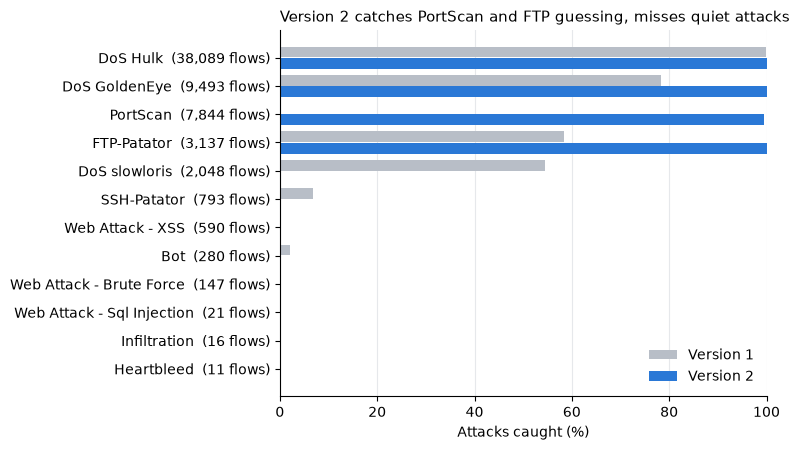

In [11]:
import matplotlib.pyplot as plt
fam = pd.read_csv(Z2 / 'hidden_by_family.csv')
fam['version'] = fam.method.str.split(',').str[0]
fam['family'] = fam.family.str.replace('\x96', '-', regex=False).str.replace(r'\s+', ' ', regex=True)
t = fam.pivot_table(index='family', columns='version', values='recall').fillna(0)
t['flows'] = fam[fam.version == 'version 2'].set_index('family').n
t = t.sort_values('flows')
display(t.round(3))
fig, ax = plt.subplots(figsize=(8, 4.6))
y = range(len(t))
ax.barh([i + 0.2 for i in y], t['version 1'] * 100, height=0.38, color='#b8bec7', label='Version 1')
ax.barh([i - 0.2 for i in y], t['version 2'] * 100, height=0.38, color='#2a78d6', label='Version 2')
ax.set_yticks(list(y), [f'{f}  ({int(n):,} flows)' for f, n in zip(t.index, t.flows)])
ax.set_xlim(0, 100); ax.set_xlabel('Attacks caught (%)')
ax.set_title('Version 2 catches PortScan and FTP guessing, misses quiet attacks', loc='left', fontsize=11)
for s in ('top', 'right'): ax.spines[s].set_visible(False)
ax.grid(axis='x', color='#e6e8eb'); ax.set_axisbelow(True)
ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.show()

In [12]:
D = pd.read_csv(Z2 / 'dev_all.csv')
s = json.load(open(Z2 / 'selected.json'))
m = D[(D.view == s['view']) & (D.consistent_features_only == s['consistent_features_only']) & (D.self_training == s['self_training']) & (D.variant == s['variant'])]
print('Development scores of the locked configuration (optimistic: chosen on these datasets)')
display(m[['target', 'sources', 'n_features', 'balanced_accuracy', 'roc_auc', 'f1', 'recall', 'fpr']].round(3))
display(pd.read_csv(Z2 / 'dev_ranking.csv').head(10).round(3))

Development scores of the locked configuration (optimistic: chosen on these datasets)


,target,sources,n_features,balanced_accuracy,roc_auc,f1,recall,fpr
302,UNSW,ToN+CIC2018+BoT,21,0.845,1.000,0.816,0.690,0.000
307,ToN,UNSW+CIC2018+BoT,11,0.798,0.893,0.903,0.948,0.352
312,CIC2018,UNSW+ToN+BoT,10,0.958,0.978,0.934,0.921,0.006
317,BoT,UNSW+ToN+CIC2018,10,0.977,0.994,0.991,0.983,0.028


,view,consistent_features_only,self_training,variant,balanced_accuracy,roc_auc
0,three windows + relative,True,True,model + computer smoothing,0.894,0.966
1,three windows + relative,True,True,model,0.882,0.966
2,three windows,True,False,model + computer smoothing,0.877,0.964
3,three windows,True,True,model + detector + smoothing,0.871,0.885
4,three windows + relative,True,True,model + detector + smoothing,0.861,0.890
5,three windows,True,True,model + computer smoothing,0.853,0.968
6,relative only,True,False,model + computer smoothing,0.852,0.941
7,relative only,True,True,model + computer smoothing,0.844,0.936
8,relative only,False,False,model + computer smoothing,0.844,0.948
9,three windows,True,True,model,0.841,0.968
